# Experiment 002 – Fine-split GBDTs, test-like validation, and a blend

| | |
|---|---|
| **Task** | Task 1 – anti-cheat pre-filter, target `is_cheater` |
| **Metric** | F2 = 5·P·R / (4P + R) – recall counts 4× more than precision |
| **Baseline** | Experiment 001: default LightGBM, nested OOF F2 **0.8364**, ROC AUC 0.8905 |
| **Question** | What lifts F2 above the default GBDT ceiling? |

What experiment 001 and the research before this notebook showed:

- All default GBDTs reach the same ceiling (nested F2 0.834–0.836). More training rows do not help: the learning curve is flat from 75% to 100% of the data.
- Each class's feature density is **piecewise uniform with steps at round numbers** (for example `crosshair_placement` 0.80 / 0.82 / 0.94 / 0.96, `reports_received` 4 / 16 / 20). The labels follow sharp thresholds.
- GBDTs put each feature into histogram bins (255 by default). Bin edges at quantiles do not line up with these round thresholds. **Finer bins let the trees cut at the true thresholds.**
- Train and test differ only in per-column NaN rates. Test has far fewer NaNs in the strong features (`account_age_days` 14.5% → 0.6%), but more in others (`headshot_percentage` 2.7% → 14.1%).

Plan:

1. Add a **test-like validation** score next to nested F2.
2. Re-test the ideas from the EDA handoff with fold-safe code: engineered features, imputation, class weights, feature drop.
3. Sweep the histogram bin count.
4. Tune LightGBM with Optuna at the best bin count.
5. Fit fine-split XGBoost and CatBoost, average LightGBM over seeds, and blend.
6. Tune one F2 threshold on the blend's OOF predictions, refit on all labeled rows, and write the submission.

Protocol: the same 5-fold `StratifiedKFold` (seed 42) as experiment 001. The test set is used for two things only: its per-column NaN rates (no labels, no values) for the test-like validation, and the final predictions.

## 0. Setup

Imports.

In [1]:
import time
from pathlib import Path

import catboost as cb
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from scipy.optimize import minimize
from sklearn.metrics import average_precision_score, fbeta_score, log_loss, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold

/Users/beam/.t3/worktrees/cpe342-ml00x/t3-7f7af2f3/task1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Paths and constants. The task root is the nearest folder with `pyproject.toml`, so the notebook runs from any working directory.

In [2]:
EXPERIMENT = "002"
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = TASK_DIR / "data"
ASSETS_DIR = TASK_DIR / "assets" / "experiments" / EXPERIMENT
PRED_DIR = TASK_DIR / "predictions" / "experiments" / EXPERIMENT
MODEL_DIR = TASK_DIR / "models" / "experiments" / EXPERIMENT
for d in (ASSETS_DIR, PRED_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET = "is_cheater"
ID_COL = "player_id"
SEED = 42
N_FOLDS = 5

Plot style. Model colors stay fixed across all charts.

In [3]:
MODEL_COLORS = {"LightGBM": "#eb6834", "XGBoost": "#1baf7a", "CatBoost": "#6250d6", "Blend": "#2a78d6"}
NEUTRAL = "#b5b4ae"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e6e6",
    "axes.titleweight": "bold",
})
pd.set_option("display.float_format", "{:.4f}".format)
optuna.logging.set_verbosity(optuna.logging.WARNING)

Helper: save report figures as PNG, 300 dpi, tight box.

In [4]:
def save_fig(fig, name):
    path = ASSETS_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved {path.relative_to(TASK_DIR)}")

## 1. Data

Load train and test. Keep only labeled train rows for fitting. The 13,184 unlabeled train rows stay out of this experiment.

In [5]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
assert list(test.columns) == [ID_COL, *FEATURES]

lab = train.dropna(subset=[TARGET]).reset_index(drop=True)
X = lab[FEATURES]
y = lab[TARGET].astype(int).to_numpy()
print(f"labeled rows: {len(lab):,}   features: {len(FEATURES)}   cheater rate: {y.mean():.3f}   test rows: {len(test):,}")

labeled rows: 90,816   features: 31   cheater rate: 0.349   test rows: 25,889


Same folds as experiment 001: `StratifiedKFold`, 5 splits, seed 42. The OOF predictions of both experiments are directly comparable.

In [6]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_id = np.empty(len(y), dtype=int)
for k, (_, val_idx) in enumerate(skf.split(X, y)):
    fold_id[val_idx] = k
np.bincount(fold_id)

array([18164, 18163, 18163, 18163, 18163])

## 2. Metrics

`best_threshold` returns the F2-optimal threshold over all distinct predictions. It takes optional row weights for the
test-like score below. `nested_f2` tunes the threshold on four folds and scores the fifth, so the score is honest.

In [7]:
def f2_curve(y_true, proba, weight=None):
    w = np.ones(len(y_true)) if weight is None else np.asarray(weight, dtype=float)
    order = np.argsort(-proba, kind="stable")
    yt, p, w = y_true[order], proba[order], w[order]
    tp = np.cumsum(w * yt)
    fp = np.cumsum(w * (1 - yt))
    pos = (w * yt).sum()
    last = np.r_[p[1:] != p[:-1], True]          # one point per distinct threshold
    tp, fp, thr = tp[last], fp[last], p[last]
    precision, recall = tp / (tp + fp), tp / pos
    f2 = 5 * tp / (5 * tp + 4 * (pos - tp) + fp)
    return thr, f2, precision, recall


def best_threshold(y_true, proba, weight=None):
    thr, f2, _, _ = f2_curve(y_true, proba, weight)
    i = np.argmax(f2)
    return thr[i], f2[i]


def nested_f2(y_true, proba, weight=None):
    w = np.ones(len(y_true)) if weight is None else weight
    pred = np.zeros(len(y_true), dtype=int)
    for k in range(N_FOLDS):
        inside = fold_id != k
        t, _ = best_threshold(y_true[inside], proba[inside], w[inside])
        pred[~inside] = proba[~inside] >= t
    return fbeta_score(y_true, pred, beta=2, sample_weight=w)

### Test-like validation

Train and test values come from the same distribution. Only the per-column NaN rates differ, and NaNs look random
(MCAR, see the EDA). So we can make the validation rows look like test rows:

- **Features with more NaNs in test** (11 features): mask extra observed values in the validation fold at random, until
  the NaN rate matches test.
- **Features with fewer NaNs in test** (20 features): we cannot un-mask values. Instead, weight each validation row by
  how likely its NaN pattern is under test rates vs train rates (importance weight, features assumed independent).

Each model then also predicts this re-masked copy of its validation fold. The weighted score is the **test-like F2**.
Only the test NaN rates are used – no test labels or values.

In [8]:
p_train = lab[FEATURES].isna().mean().to_numpy()
p_test = test[FEATURES].isna().mean().to_numpy()
up = p_test > p_train
print("more NaNs in test:", [f for f, u in zip(FEATURES, up) if u])

rng = np.random.default_rng(SEED)
extra_mask = (rng.random(X.shape) < np.where(up, (p_test - p_train) / (1 - p_train), 0)) & X.notna().to_numpy()
X_testlike = X.mask(extra_mask)

is_nan = X.isna().to_numpy()
log_w = np.where(is_nan, np.log(p_test / p_train), np.log((1 - p_test) / (1 - p_train)))[:, ~up].sum(axis=1)
w_testlike = np.exp(log_w - log_w.max())
w_testlike /= w_testlike.mean()
print(f"effective sample size of the weights: {w_testlike.sum() ** 2 / (w_testlike ** 2).sum():,.0f} rows")

check = pd.DataFrame({
    "train": p_train,
    "test-like": np.average(X_testlike.isna().to_numpy(), axis=0, weights=w_testlike),
    "test": p_test,
}, index=FEATURES)
print(f"largest |test-like − test| NaN-rate gap: {(check['test-like'] - check['test']).abs().max():.4f}")
check.sort_values("test").T

more NaNs in test: ['headshot_percentage', 'win_rate', 'accuracy_score', 'kill_consistency', 'device_changes_count', 'night_play_ratio', 'game_sense_score', 'clutch_success_rate', 'first_blood_rate', 'damage_per_round', 'utility_usage_rate']
effective sample size of the weights: 21,330 rows
largest |test-like − test| NaN-rate gap: 0.0039


,account_age_days,map_knowledge,level,sessions_per_day,avg_session_length_min,aiming_smoothness,accuracy_score,crosshair_placement,friend_network_size,kill_death_ratio,...,buy_decision_score,damage_per_round,survival_time_avg,clutch_success_rate,device_changes_count,win_rate,utility_usage_rate,headshot_percentage,reports_received,weapon_switch_speed
train,0.1447,0.0779,0.0717,0.0328,0.2294,0.2081,0.0061,0.1281,0.2229,0.0961,...,0.1268,0.0911,0.2426,0.0248,0.0293,0.0495,0.1112,0.0274,0.2229,0.2422
test-like,0.0056,0.0066,0.0154,0.0148,0.0159,0.0211,0.0225,0.0279,0.0488,0.0539,...,0.1079,0.1252,0.1300,0.1329,0.1371,0.1346,0.1370,0.1397,0.1489,0.1563
test,0.0056,0.0064,0.0151,0.0156,0.0158,0.0206,0.0228,0.0278,0.0474,0.0531,...,0.1112,0.1283,0.1306,0.1353,0.1358,0.1374,0.1409,0.1411,0.1493,0.1549


## 3. Cross-validation runner

`run_cv` fits one fresh model per fold. An optional `prep` function is fit on the training fold only and transforms
all frames (for fold-safe feature engineering or imputation). Each fold model predicts the normal validation rows and
the test-like copy. `score` turns the two OOF vectors into one results row.

In [9]:
def run_cv(name, make_model, prep=None, X_in=None, verbose=True):
    X_all = X if X_in is None else X_in
    X_tl = X_testlike if X_in is None else X_in.mask(np.c_[extra_mask, np.zeros((len(X_in), X_in.shape[1] - X.shape[1]), bool)])
    oof, oof_tl = np.zeros(len(y)), np.zeros(len(y))
    start = time.perf_counter()
    for k in range(N_FOLDS):
        trn, val = fold_id != k, fold_id == k
        Xt, Xv, Xvt = X_all[trn], X_all[val], X_tl[val]
        if prep is not None:
            transform = prep(Xt, y[trn])
            Xt, Xv, Xvt = transform(Xt), transform(Xv), transform(Xvt)
        model = make_model()
        model.fit(Xt, y[trn])
        oof[val] = model.predict_proba(Xv)[:, 1]
        oof_tl[val] = model.predict_proba(Xvt)[:, 1]
    seconds = time.perf_counter() - start
    row = score(name, oof, oof_tl, seconds)
    if verbose:
        print(f"{name:42s} AUC {row['roc_auc']:.4f}  nested F2 {row['nested_f2']:.4f}  "
              f"test-like F2 {row['testlike_f2']:.4f}  ({seconds:.0f}s)")
    return oof, oof_tl, row


def score(name, oof, oof_tl, seconds=np.nan):
    t, f2 = best_threshold(y, oof)
    t_tl, _ = best_threshold(y, oof_tl, w_testlike)
    return {
        "model": name,
        "roc_auc": roc_auc_score(y, oof),
        "pr_auc": average_precision_score(y, oof),
        "best_f2": f2,
        "threshold": t,
        "nested_f2": nested_f2(y, oof),
        "testlike_auc": roc_auc_score(y, oof_tl, sample_weight=w_testlike),
        "testlike_f2": nested_f2(y, oof_tl, w_testlike),
        "testlike_threshold": t_tl,
        "fit_seconds": seconds,
    }

## 4. Baseline

Default LightGBM with the default 255 bins – the experiment 001 submission model. This must reproduce nested F2 0.8364.

In [10]:
def lgbm(**params):
    return lambda: lgb.LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, **params)


oof_base, oof_base_tl, row = run_cv("LightGBM default (exp 001)", lgbm())
ablation = [row]

LightGBM default (exp 001)                 AUC 0.8905  nested F2 0.8364  test-like F2 0.8492  (6s)


## 5. Handoff ideas, re-tested

The EDA handoff proposed these changes. Each runs on the same default LightGBM, so only the one change differs.
Fold-safe: anything learned from labels or value statistics is fit on the training fold only.

**Engineered features.** `level_progression_speed ≈ level / account_age_days × U(0.15, 1.08)` in the data
(log correlation 0.92). So a missing `account_age_days` can be estimated from `level / level_progression_speed`. Ratios
from the account-maturity block follow the EDA suggestion.

In [11]:
def add_features(frame):
    out = frame.copy()
    age = out["account_age_days"].fillna(0.615 * out["level"] / out["level_progression_speed"])
    out["age_filled"] = age
    out["speed_multiplier"] = out["level_progression_speed"] * out["account_age_days"] / out["level"]
    out["friends_per_day"] = out["friend_network_size"] / age
    out["reports_per_day"] = out["reports_received"] / age
    out["level_per_day"] = out["level"] / age
    return out


X_fe = add_features(X)
_, _, row = run_cv("+ engineered features (age fill, ratios)", lgbm(), X_in=X_fe)
ablation.append(row)

+ engineered features (age fill, ratios)   AUC 0.8910  nested F2 0.8362  test-like F2 0.8504  (6s)


**Class-only range hits.** For each feature, find the value ranges that only one class reaches **in the training
fold**. Count per row how many features fall in a legit-only range and in a cheater-only range.

In [12]:
def range_hits_prep(Xt, yt):
    lo1, hi1 = Xt[yt == 1].min(), Xt[yt == 1].max()
    lo0, hi0 = Xt[yt == 0].min(), Xt[yt == 0].max()

    def transform(frame):
        out = frame.copy()
        out["legit_only_hits"] = ((frame < lo1) | (frame > hi1)).sum(axis=1)
        out["cheater_only_hits"] = ((frame < lo0) | (frame > hi0)).sum(axis=1)
        return out

    return transform


_, _, row = run_cv("+ class-only range hit counts", lgbm(), prep=range_hits_prep)
ablation.append(row)

+ class-only range hit counts              AUC 0.8905  nested F2 0.8360  test-like F2 0.8499  (5s)


**Median imputation** instead of LightGBM's native NaN handling. Medians come from the training fold.

In [13]:
def median_prep(Xt, yt):
    med = Xt.median()
    return lambda frame: frame.fillna(med)


_, _, row = run_cv("median imputation", lgbm(), prep=median_prep)
ablation.append(row)

median imputation                          AUC 0.8890  nested F2 0.8352  test-like F2 0.8460  (5s)


**Class weight.** `scale_pos_weight` = negatives / positives ≈ 1.86, so both classes weigh the same in the loss.

In [14]:
_, _, row = run_cv("scale_pos_weight = 1.86", lgbm(scale_pos_weight=(y == 0).sum() / (y == 1).sum()))
ablation.append(row)

scale_pos_weight = 1.86                    AUC 0.8905  nested F2 0.8370  test-like F2 0.8496  (5s)


**Drop weak features.** The EDA permutation importance put about 15 features at ≈ 0. Keep the 14 features with
importance > 0.0008. (The importance came from all labeled rows, so this test is slightly optimistic.)

In [15]:
importance = pd.read_csv(TASK_DIR / "assets" / "eda" / "permutation-importance.csv", index_col=0)["importance"]
KEEP = importance[importance > 0.0008].index.tolist()
_, _, row = run_cv(f"drop weak features (keep {len(KEEP)})", lgbm(), prep=lambda Xt, yt: (lambda frame: frame[KEEP]))
ablation.append(row)

drop weak features (keep 14)               AUC 0.8910  nested F2 0.8370  test-like F2 0.8494  (5s)


Ablation table. `Δ nested F2` is the change against the baseline. The fold-to-fold std of F2 is about 0.0014 (experiment 001), so changes smaller than that are noise.

In [16]:
ablation_df = pd.DataFrame(ablation).set_index("model")
ablation_df["delta_nested_f2"] = ablation_df["nested_f2"] - ablation_df.loc["LightGBM default (exp 001)", "nested_f2"]
ablation_df["delta_testlike_f2"] = ablation_df["testlike_f2"] - ablation_df.loc["LightGBM default (exp 001)", "testlike_f2"]
ablation_df.to_csv(ASSETS_DIR / "ablation-handoff-ideas.csv")
ablation_df[["roc_auc", "nested_f2", "delta_nested_f2", "testlike_f2", "delta_testlike_f2"]]

,roc_auc,nested_f2,delta_nested_f2,testlike_f2,delta_testlike_f2
model,,,,,
LightGBM default (exp 001),0.8905,0.8364,0.0000,0.8492,0.0000
"+ engineered features (age fill, ratios)",0.8910,0.8362,-0.0002,0.8504,0.0012
+ class-only range hit counts,0.8905,0.8360,-0.0003,0.8499,0.0008
median imputation,0.8890,0.8352,-0.0012,0.8460,-0.0032
scale_pos_weight = 1.86,0.8905,0.8370,0.0006,0.8496,0.0005
drop weak features (keep 14),0.8910,0.8370,0.0006,0.8494,0.0002


## 6. Histogram bin resolution

LightGBM puts each feature into at most `max_bin` bins and only splits at bin edges. `min_data_in_bin` (default 3)
also merges rare values. With 255 quantile bins, the round-number thresholds of the generator fall inside bins.
Sweep `max_bin` with `min_data_in_bin=1`, on default settings otherwise.

In [17]:
BIN_GRID = [63, 255, 1023, 4095, 16383]
bin_rows = []
for mb in BIN_GRID:
    _, _, row = run_cv(f"LightGBM max_bin={mb}", lgbm(max_bin=mb, min_data_in_bin=1))
    row["max_bin"] = mb
    bin_rows.append(row)
bins_df = pd.DataFrame(bin_rows).set_index("max_bin")
bins_df.to_csv(ASSETS_DIR / "bin-resolution-sweep.csv")
bins_df[["roc_auc", "nested_f2", "testlike_f2", "fit_seconds"]]

LightGBM max_bin=63                        AUC 0.8837  nested F2 0.8313  test-like F2 0.8415  (7s)


LightGBM max_bin=255                       AUC 0.8905  nested F2 0.8364  test-like F2 0.8492  (7s)


LightGBM max_bin=1023                      AUC 0.8917  nested F2 0.8378  test-like F2 0.8503  (7s)


LightGBM max_bin=4095                      AUC 0.8921  nested F2 0.8378  test-like F2 0.8520  (17s)


LightGBM max_bin=16383                     AUC 0.8921  nested F2 0.8378  test-like F2 0.8519  (62s)


,roc_auc,nested_f2,testlike_f2,fit_seconds
max_bin,,,,
63,0.8837,0.8313,0.8415,6.5198
255,0.8905,0.8364,0.8492,6.5652
1023,0.8917,0.8378,0.8503,7.0080
4095,0.8921,0.8378,0.8520,17.2057
16383,0.8921,0.8378,0.8519,61.8061


F2 against bin count. The dotted line is the experiment 001 baseline (255 bins, `min_data_in_bin=3`).

saved assets/experiments/002/bin-resolution-sweep.png


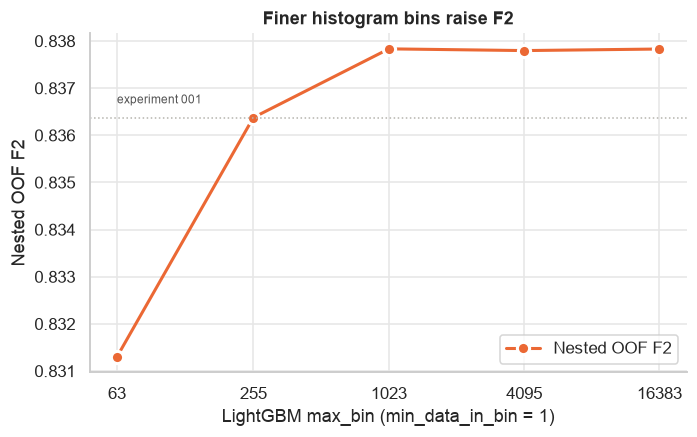

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bins_df.index, bins_df["nested_f2"], "o-", color=MODEL_COLORS["LightGBM"], linewidth=2, markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="Nested OOF F2")
ax.axhline(ablation_df.iloc[0]["nested_f2"], color=NEUTRAL, linestyle=":", linewidth=1)
ax.text(BIN_GRID[0], ablation_df.iloc[0]["nested_f2"] + 0.0003, "experiment 001", fontsize=8, color="#555")
ax.set_xscale("log", base=2)
ax.set_xticks(BIN_GRID, [str(b) for b in BIN_GRID])
ax.set(title="Finer histogram bins raise F2", xlabel="LightGBM max_bin (min_data_in_bin = 1)", ylabel="Nested OOF F2")
ax.legend(loc="lower right")
save_fig(fig, "bin-resolution-sweep")
plt.show()

Pick the bin count with the best nested F2 for all later LightGBM runs.

In [19]:
MAX_BIN = int(bins_df["nested_f2"].idxmax())
print(f"MAX_BIN = {MAX_BIN}")

MAX_BIN = 1023


## 7. Optuna tuning (LightGBM)

Tune LightGBM at the chosen bin count. Objective: OOF ROC AUC on the same 5 folds. AUC is smoother than F2 at
one threshold, so it is a less noisy target; F2 is logged for each trial too. Each trial prints one line, so long
runs show progress. TPE sampler, seed 42.

In [20]:
N_TRIALS = 30


def lgbm_space(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 1.0),
    }


def objective(trial):
    params = lgbm_space(trial)
    oof = np.zeros(len(y))
    for k in range(N_FOLDS):
        trn, val = fold_id != k, fold_id == k
        model = lgbm(max_bin=MAX_BIN, min_data_in_bin=1, **params)().fit(X[trn], y[trn])
        oof[val] = model.predict_proba(X[val])[:, 1]
    trial.set_user_attr("best_f2", best_threshold(y, oof)[1])
    return roc_auc_score(y, oof)


def log_trial(study, trial):
    print(f"trial {trial.number:2d}  AUC {trial.value:.4f}  F2 {trial.user_attrs['best_f2']:.4f}  best AUC {study.best_value:.4f}")


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31, "min_child_samples": 20,
                     "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 1e-3, "min_split_gain": 0.0})
study.optimize(objective, n_trials=N_TRIALS, callbacks=[log_trial])
LGBM_PARAMS = {**study.best_params, "subsample_freq": 1}
print("best params:", LGBM_PARAMS)

/var/folders/js/tpfy4qxs76jf4199skp9p6n40000gn/T/ipykernel_64190/4167048495.py:6: UserWarning: Fixed parameter n_estimators with value 100 is out of range for distribution IntDistribution(high=1500, log=True, low=200, step=1).
  "n_estimators": trial.suggest_int("n_estimators", 200, 1500, log=True),


trial  0  AUC 0.8918  F2 0.8380  best AUC 0.8918


trial  1  AUC 0.8838  F2 0.8336  best AUC 0.8918


trial  2  AUC 0.8887  F2 0.8338  best AUC 0.8918


trial  3  AUC 0.8917  F2 0.8360  best AUC 0.8918


trial  4  AUC 0.8881  F2 0.8328  best AUC 0.8918


... (21 outputs left out)

trial 26  AUC 0.8932  F2 0.8386  best AUC 0.8932


trial 27  AUC 0.8924  F2 0.8385  best AUC 0.8932


trial 28  AUC 0.8922  F2 0.8385  best AUC 0.8932


trial 29  AUC 0.8906  F2 0.8371  best AUC 0.8932
best params: {'n_estimators': 341, 'learning_rate': 0.024228493567741104, 'num_leaves': 41, 'min_child_samples': 7, 'subsample': 0.7774105297412587, 'colsample_bytree': 0.8744173982668203, 'reg_lambda': 4.443153427614608, 'min_split_gain': 0.36881473096174894, 'subsample_freq': 1}


Save all trials for the report.

In [21]:
trials = study.trials_dataframe(attrs=("number", "value", "user_attrs", "params"))
trials.to_csv(ASSETS_DIR / "optuna-lightgbm-trials.csv", index=False)
trials.sort_values("value", ascending=False).head(5)

,number,value,user_attrs_best_f2,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_min_split_gain,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample
26,26,0.8932,0.8386,0.8744,0.0242,7,0.3688,341,41,4.4432,0.7774
20,20,0.8928,0.8388,0.8891,0.0140,5,0.4868,328,71,1.1129,0.6808
14,14,0.8926,0.8387,0.9745,0.0149,5,0.3917,479,59,5.0266,0.6956
24,24,0.8926,0.8388,0.9284,0.0181,12,0.5256,456,56,2.3274,0.6325
25,25,0.8925,0.8384,0.9369,0.0174,5,0.4365,554,69,1.6141,0.7225


## 8. Final model families

Every family gets fine splits:

- **LightGBM**: tuned settings, `max_bin = MAX_BIN`, averaged over 5 seeds. Seed averaging smooths the
  row and column subsampling noise.
- **XGBoost**: `hist` with 4,096 bins (probe: 256 → 4,096 bins raised nested F2 from 0.8356 to 0.8368).
- **CatBoost**: 1,024 borders (default 254).

In [22]:
SEEDS = [42, 7, 2024, 31337, 9]
oof_lgb, oof_lgb_tl = np.zeros(len(y)), np.zeros(len(y))
start = time.perf_counter()
for s in SEEDS:
    make = lambda s=s: lgb.LGBMClassifier(random_state=s, n_jobs=-1, verbose=-1, max_bin=MAX_BIN, min_data_in_bin=1, **LGBM_PARAMS)
    o, o_tl, row = run_cv(f"LightGBM tuned, seed {s}", make)
    oof_lgb += o / len(SEEDS)
    oof_lgb_tl += o_tl / len(SEEDS)
final_rows = [score("LightGBM tuned (5 seeds)", oof_lgb, oof_lgb_tl, time.perf_counter() - start)]
print({k: round(v, 4) for k, v in final_rows[-1].items() if k != "model"})

LightGBM tuned, seed 42                    AUC 0.8932  nested F2 0.8385  test-like F2 0.8506  (26s)


LightGBM tuned, seed 7                     AUC 0.8930  nested F2 0.8382  test-like F2 0.8504  (26s)


LightGBM tuned, seed 2024                  AUC 0.8928  nested F2 0.8377  test-like F2 0.8495  (28s)


LightGBM tuned, seed 31337                 AUC 0.8930  nested F2 0.8384  test-like F2 0.8511  (28s)


LightGBM tuned, seed 9                     AUC 0.8928  nested F2 0.8386  test-like F2 0.8507  (28s)


{'roc_auc': 0.8932, 'pr_auc': 0.8353, 'best_f2': np.float64(0.8387), 'threshold': np.float64(0.1811), 'nested_f2': 0.8383, 'testlike_auc': 0.9131, 'testlike_f2': 0.8513, 'testlike_threshold': np.float64(0.1914), 'fit_seconds': 137.2025}


XGBoost with 4,096 bins. Settings are moderate and fixed: depth 7, learning rate 0.02, 600 trees.

In [23]:
XGB_PARAMS = dict(n_estimators=600, learning_rate=0.02, max_depth=7, min_child_weight=2, subsample=0.7,
                  colsample_bytree=0.9, reg_lambda=5, tree_method="hist", max_bin=4096)
make_xgb = lambda: xgb.XGBClassifier(random_state=SEED, n_jobs=-1, **XGB_PARAMS)
oof_xgb, oof_xgb_tl, row = run_cv("XGBoost hist 4096 bins", make_xgb)
final_rows.append(row)

XGBoost hist 4096 bins                     AUC 0.8922  nested F2 0.8368  test-like F2 0.8492  (130s)


CatBoost with 1,024 borders. `allow_writing_files=False` stops the `catboost_info/` log folder.

In [24]:
CB_PARAMS = dict(iterations=1500, learning_rate=0.05, depth=6, border_count=1024)
make_cb = lambda: cb.CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False, **CB_PARAMS)
oof_cb, oof_cb_tl, row = run_cv("CatBoost 1024 borders", make_cb)
final_rows.append(row)

CatBoost 1024 borders                      AUC 0.8888  nested F2 0.8361  test-like F2 0.8484  (125s)


## 9. Blend

Weighted average of the three probability vectors. The weights minimize OOF log loss (smooth, so less noisy than
F2), constrained to be ≥ 0 and sum to 1. A probability average keeps OOF and test predictions on the same scale,
so the OOF threshold transfers to test.

In [25]:
FAMILIES = ["LightGBM", "XGBoost", "CatBoost"]
oof_stack = np.c_[oof_lgb, oof_xgb, oof_cb]
oof_stack_tl = np.c_[oof_lgb_tl, oof_xgb_tl, oof_cb_tl]

res = minimize(lambda w: log_loss(y, np.clip(oof_stack @ w, 1e-7, 1 - 1e-7)), x0=np.ones(3) / 3,
               bounds=[(0, 1)] * 3, constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
BLEND_WEIGHTS = dict(zip(FAMILIES, np.round(res.x, 3)))
print("blend weights:", BLEND_WEIGHTS)
w_vec = np.array(list(BLEND_WEIGHTS.values()))
oof_blend, oof_blend_tl = oof_stack @ w_vec, oof_stack_tl @ w_vec
final_rows.append(score("Blend", oof_blend, oof_blend_tl))

blend weights: {'LightGBM': np.float64(0.972), 'XGBoost': np.float64(0.0), 'CatBoost': np.float64(0.028)}


How similar are the families? Lower correlation means more to gain from the blend.

In [26]:
pd.DataFrame(oof_stack, columns=FAMILIES).corr(method="spearman")

,LightGBM,XGBoost,CatBoost
LightGBM,1.0000,0.9953,0.9785
XGBoost,0.9953,1.0000,0.9795
CatBoost,0.9785,0.9795,1.0000


## 10. Results

All rows use OOF predictions. Compare models on `nested_f2` (normal folds) and `testlike_f2` (folds re-masked to
test NaN rates). The experiment 001 baseline is the first row.

In [27]:
results = pd.DataFrame([ablation[0], *final_rows]).set_index("model")
results.to_csv(ASSETS_DIR / "results.csv")
results[["roc_auc", "pr_auc", "nested_f2", "threshold", "testlike_auc", "testlike_f2", "testlike_threshold"]]

,roc_auc,pr_auc,nested_f2,threshold,testlike_auc,testlike_f2,testlike_threshold
model,,,,,,,
LightGBM default (exp 001),0.8905,0.8315,0.8364,0.1948,0.9111,0.8492,0.1937
LightGBM tuned (5 seeds),0.8932,0.8353,0.8383,0.1811,0.9131,0.8513,0.1914
XGBoost hist 4096 bins,0.8922,0.8338,0.8368,0.2001,0.9123,0.8492,0.1892
CatBoost 1024 borders,0.8888,0.8289,0.8361,0.1651,0.9095,0.8484,0.1888
Blend,0.8933,0.8354,0.8382,0.1910,0.9131,0.8518,0.1929


Fold-to-fold stability of the blend vs the baseline: F2 per fold at that fold's own best threshold.

In [28]:
per_fold = pd.DataFrame({
    name: [best_threshold(y[fold_id == k], p[fold_id == k])[1] for k in range(N_FOLDS)]
    for name, p in {"exp 001 baseline": oof_base, "Blend": oof_blend}.items()
}).rename_axis("fold")
per_fold["gain"] = per_fold["Blend"] - per_fold["exp 001 baseline"]
per_fold.loc["mean"] = per_fold.mean()
per_fold

,exp 001 baseline,Blend,gain
fold,,,
0,0.8364,0.8377,0.0014
1,0.8373,0.8402,0.0029
2,0.8388,0.8404,0.0016
3,0.8355,0.8381,0.0025
4,0.8387,0.8405,0.0018
mean,0.8374,0.8394,0.0020


F2 against the decision threshold near the optimum, on normal and test-like folds.

saved assets/experiments/002/f2-threshold-curves.png


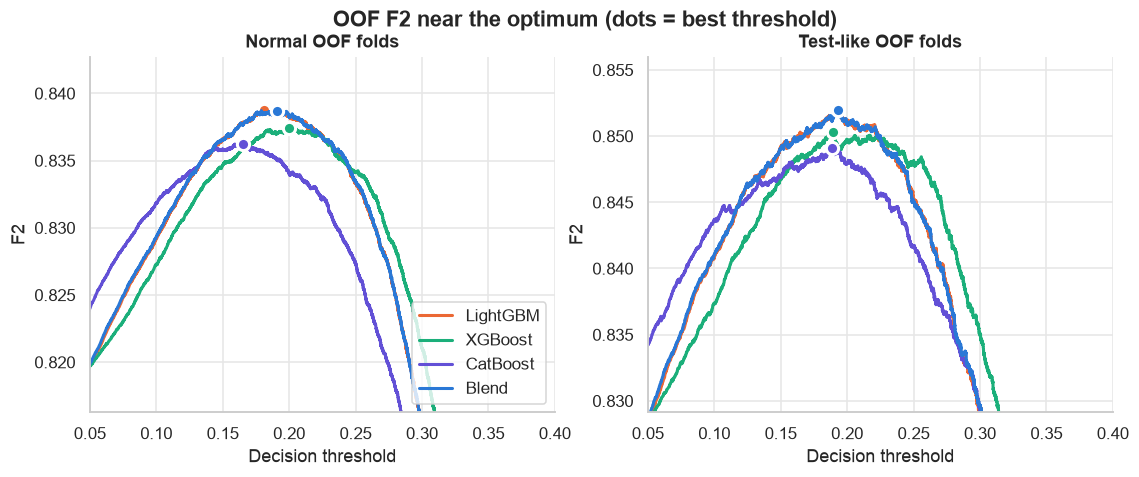

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
curves = {"LightGBM": (oof_lgb, oof_lgb_tl), "XGBoost": (oof_xgb, oof_xgb_tl),
          "CatBoost": (oof_cb, oof_cb_tl), "Blend": (oof_blend, oof_blend_tl)}
for ax, (title, idx, weight) in zip(axes, [("Normal OOF folds", 0, None), ("Test-like OOF folds", 1, w_testlike)]):
    tops = []
    for name, preds in curves.items():
        thr, f2, _, _ = f2_curve(y, preds[idx], weight)
        ax.plot(thr, f2, color=MODEL_COLORS[name], linewidth=2, label=name)
        i = np.argmax(f2)
        ax.plot(thr[i], f2[i], "o", color=MODEL_COLORS[name], markersize=8, markeredgecolor="white", markeredgewidth=2)
        tops.append(f2[i])
    ax.set(title=title, xlabel="Decision threshold", ylabel="F2", xlim=(0.05, 0.4), ylim=(min(tops) - 0.02, max(tops) + 0.004))
axes[0].legend(loc="lower right")
fig.suptitle("OOF F2 near the optimum (dots = best threshold)", fontweight="bold")
save_fig(fig, "f2-threshold-curves")
plt.show()

## 11. Save OOF predictions

In [30]:
oof_out = pd.DataFrame({ID_COL: lab[ID_COL], "fold": fold_id, TARGET: y,
                        "oof_LightGBM": oof_lgb, "oof_XGBoost": oof_xgb, "oof_CatBoost": oof_cb, "oof_Blend": oof_blend})
oof_out.to_csv(PRED_DIR / "oof.csv", index=False)
print(f"saved {(PRED_DIR / 'oof.csv').relative_to(TASK_DIR)}  {oof_out.shape}")

saved predictions/experiments/002/oof.csv  (90816, 7)


## 12. Submission (blend)

Threshold: tuned on the blend's normal OOF predictions, as the competition rules require. The test-like threshold
is printed as a check. If both are close, the threshold transfers to test.

In [31]:
SUBMIT_THRESHOLD, submit_f2 = best_threshold(y, oof_blend)
tl_threshold, _ = best_threshold(y, oof_blend_tl, w_testlike)
print(f"threshold {SUBMIT_THRESHOLD:.4f} (OOF F2 {submit_f2:.4f})   test-like threshold {tl_threshold:.4f}")

threshold 0.1910 (OOF F2 0.8387)   test-like threshold 0.1929


Refit every family on **all** labeled rows and save the models. The test set is used only for prediction.

In [32]:
final_models = {"LightGBM": [lgb.LGBMClassifier(random_state=s, n_jobs=-1, verbose=-1, max_bin=MAX_BIN, min_data_in_bin=1,
                                                **LGBM_PARAMS).fit(X, y) for s in SEEDS],
                "XGBoost": [make_xgb().fit(X, y)],
                "CatBoost": [make_cb().fit(X, y)]}
for name, models in final_models.items():
    joblib.dump(models, MODEL_DIR / f"{name.lower()}.joblib")
joblib.dump({"weights": BLEND_WEIGHTS, "threshold": SUBMIT_THRESHOLD, "features": FEATURES}, MODEL_DIR / "blend.joblib")
print("saved", sorted(p.name for p in MODEL_DIR.iterdir()))

saved ['blend.joblib', 'catboost.joblib', 'lightgbm.joblib', 'xgboost.joblib']


Predict test with each family, then blend with the OOF weights.

In [33]:
test_family = {name: np.mean([m.predict_proba(test[FEATURES])[:, 1] for m in models], axis=0)
               for name, models in final_models.items()}
test_proba = sum(BLEND_WEIGHTS[name] * test_family[name] for name in FAMILIES)
pd.DataFrame({ID_COL: test[ID_COL], **{f"proba_{n}": p for n, p in test_family.items()}, "proba_Blend": test_proba}
             ).to_csv(PRED_DIR / "test.csv", index=False)
print(f"saved {(PRED_DIR / 'test.csv').relative_to(TASK_DIR)}")

saved predictions/experiments/002/test.csv


Sanity check: the share flagged on test vs OOF at the same threshold. Test has fewer NaNs in the strong features, so
predictions are more confident there and the share can move. Compare with the test-like OOF share, which models that.

In [34]:
print(f"flagged on OOF          : {(oof_blend >= SUBMIT_THRESHOLD).mean():.3f}")
print(f"flagged on test-like OOF: {np.average(oof_blend_tl >= SUBMIT_THRESHOLD, weights=w_testlike):.3f}")
print(f"flagged on test         : {(test_proba >= SUBMIT_THRESHOLD).mean():.3f}")

flagged on OOF          : 0.634
flagged on test-like OOF: 0.597
flagged on test         : 0.600


Write `submit/index.csv` (`id,task1`). Test row *i* maps to the *i*-th sample id (`ANS00001…`), as in experiment 001.
Also show how many test labels change vs the experiment 001 submission.

In [35]:
sample = pd.read_csv(TASK_DIR.parent / "submission" / "sample_submission.csv", usecols=["id"])
assert len(sample) == len(test)
SUBMIT_PATH = TASK_DIR / "submit" / "index.csv"
previous = pd.read_csv(SUBMIT_PATH)

submit = pd.DataFrame({"id": sample["id"], "task1": (test_proba >= SUBMIT_THRESHOLD).astype(int)})
submit.to_csv(SUBMIT_PATH, index=False)
changed = (previous["task1"].to_numpy() != submit["task1"].to_numpy())
print(f"saved {SUBMIT_PATH.relative_to(TASK_DIR)}  rows {len(submit):,}  share of 1s {submit.task1.mean():.3f}  "
      f"changed vs exp 001: {changed.sum():,} ({changed.mean():.1%})")

saved submit/index.csv  rows 25,889  share of 1s 0.600  changed vs exp 001: 471 (1.8%)


## 13. Conclusion


| Model | OOF ROC AUC | Nested F2 | Test-like F2 | Threshold |
|---|---|---|---|---|
| LightGBM default (exp 001) | 0.8905 | 0.8364 | 0.8492 | 0.195 |
| LightGBM tuned, 1,023 bins, 5 seeds | 0.8932 | **0.8383** | 0.8513 | 0.181 |
| XGBoost hist, 4,096 bins | 0.8922 | 0.8368 | 0.8492 | 0.200 |
| CatBoost, 1,024 borders | 0.8888 | 0.8361 | 0.8484 | 0.165 |
| **Blend** (0.972 LightGBM + 0.028 CatBoost) | **0.8933** | 0.8382 | **0.8518** | 0.191 |

**Findings**

- **Bin resolution is the main gain.** LightGBM `max_bin` 255 → 1,023 with `min_data_in_bin=1` raises nested F2
  from 0.8364 to 0.8378 on default settings. 63 bins lose 0.005. The class densities are piecewise uniform with steps
  at round numbers, and finer bins let the trees cut at those steps. The gain levels off at about 1,000 bins (nested F2)
  and about 4,000 bins (test-like F2).
- **Tuning and seed averaging add a little more:** 0.8378 → 0.8383. Optuna trials cluster at AUC 0.892–0.893, so the
  settings are not sensitive.
- **The blend gains vs experiment 001 on every fold:** +0.0014 to +0.0029 per fold, mean +0.0020. That is about
  1.5× the fold-to-fold std, so the gain is real but small. The blend itself adds almost nothing over tuned LightGBM:
  XGBoost gets weight 0 (Spearman 0.995 with LightGBM).
- **Handoff ideas do not help** (table in section 5): engineered ratios, class-only range counts, class weight, and
  feature drop are all within ±0.0006 nested F2. **Median imputation hurts** (−0.0012 nested, −0.0032 test-like), so
  keep LightGBM's native NaN handling.
- **Test-like validation:** every model scores about 0.013 F2 higher on test-like folds. Test has fewer NaNs in the
  strong features. The test-like threshold (0.193) matches the normal one (0.191), and the share of flagged test rows
  (0.600) matches the test-like OOF share (0.597). So the threshold transfers to test. Expect a leaderboard F2 near 0.85.

**Probes run outside this notebook (not kept):** ExtraTrees, RandomForest, and an MLP all score lower (nested F2
0.795–0.824) and do not help in any blend. A smooth spline-logistic model (GAM) is worse than LightGBM even on the
ambiguous rows. A latent-class mixture of histogram Naive Bayes models reaches AUC 0.864 at K = 3 components (0.841 at
K = 1), still far below the GBDTs.

**Submission:** the blend, refit on all labeled rows, threshold 0.191 → `submit/index.csv`. It flags 60.0% of test
rows and changes 471 labels (1.8%) vs experiment 001.

**Ideas for experiment 003**

1. Force bin edges at the generator's round-number steps (LightGBM `forcedbins_filename`), instead of relying on many
   quantile bins.
2. Pseudo-label the 13,184 unlabeled train rows with confident blend predictions (train rows only).
3. A faster, vectorized latent-class model with more components. Use its component posteriors as features for
   the rows with NaNs in the top features, where F2 is lowest.
4. Use 4,095 bins: same nested F2 as 1,023, but +0.0017 test-like F2 on default settings.
